# Feature Importance and Feature Reduction

## 1. Objective

The objective is to investigate whether the current 39 encoded model features can be reduced while retaining useful predictive information. This is a separate research experiment; it does not change the grouped dataset or the 39-feature baseline.

Feature importance, backward elimination, and candidate selection use training data and an internal validation split only. The outer test set is held untouched until the selected subset is locked and the six final models are evaluated once.

## 2. Source Feature Set

The experiment starts from the same 14 source variables used by the baseline. Temporal-derived values are numeric features created from the incident date/time. `dc_dist` and `psa` are categorical; the coordinate fields are numeric.

In [1]:
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

try:
    from _bootstrap import ensure_project_root
except ModuleNotFoundError:
    from notebooks._bootstrap import ensure_project_root
project_root = ensure_project_root()

from src.config import (
    GROUPED_DATASET, RESULTS_DIR, TARGET_GROUPED, RANDOM_STATE, TEST_SIZE,
    NUMERICAL_FEATURES, CATEGORICAL_FEATURES, IDENTIFIER_COLUMNS, LEAKAGE_COLUMNS,
)
from src.data_loader import load_grouped_philadelphia_data
from src.data_validation import validate_target, check_target_leakage
from src.feature_engineering import create_temporal_features
from src.preprocessing import (
    build_preprocessor, build_encoded_subset_pipeline, create_train_test_split,
)
from src.feature_selection import (
    rank_feature_importances, compare_feature_importance, backward_elimination,
    correlation_matrix, find_correlated_feature_pairs,
)
from src.evaluation import evaluate_multiclass_model, add_model_result
from src.visualization import (
    plot_feature_importance, plot_correlation_heatmap, plot_feature_count_validation,
    plot_baseline_reduced_comparison,
)
from models.random_forest_model import create_model as create_random_forest_model
from models.xgboost_model import create_model as create_xgboost_model
from models.catboost_model import create_model as create_catboost_model
from models.decision_tree_model import create_model as create_decision_tree_model
from models.mlp_model import create_model as create_mlp_model
from models.knn_model import create_model as create_knn_model

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 50)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
source_feature_rows = [
    ("year", "Temporal-derived", "Calendar year from dispatch_date", "Yes"),
    ("month", "Temporal-derived", "Calendar month from dispatch_date", "Yes"),
    ("day_of_week", "Temporal-derived", "Monday=0 through Sunday=6", "Yes"),
    ("day_of_month", "Temporal-derived", "Day number within the month", "Yes"),
    ("day_of_year", "Temporal-derived", "Ordinal day within the year", "Yes"),
    ("week_of_year", "Temporal-derived", "ISO week number", "Yes"),
    ("hour", "Temporal-derived", "Reported incident hour (0–23)", "Yes"),
    ("minute", "Temporal-derived", "Minute from dispatch_time", "Yes"),
    ("dc_dist", "Categorical", "Police district identifier", "Yes"),
    ("psa", "Categorical", "Police service area identifier", "Yes"),
    ("lat", "Numerical", "Latitude coordinate", "Yes"),
    ("lng", "Numerical", "Longitude coordinate", "Yes"),
    ("point_x", "Numerical", "Projected x coordinate", "Yes"),
    ("point_y", "Numerical", "Projected y coordinate", "Yes"),
]
source_feature_table = pd.DataFrame(source_feature_rows, columns=["Feature", "Type", "Description", "Used?"])
display(source_feature_table)


,Feature,Type,Description,Used?
0,year,Temporal-derived,Calendar year from dispatch_date,Yes
1,month,Temporal-derived,Calendar month from dispatch_date,Yes
2,day_of_week,Temporal-derived,Monday=0 through Sunday=6,Yes
3,day_of_month,Temporal-derived,Day number within the month,Yes
4,day_of_year,Temporal-derived,Ordinal day within the year,Yes
5,week_of_year,Temporal-derived,ISO week number,Yes
6,hour,Temporal-derived,Reported incident hour (0–23),Yes
7,minute,Temporal-derived,Minute from dispatch_time,Yes
8,dc_dist,Categorical,Police district identifier,Yes
9,psa,Categorical,Police service area identifier,Yes


## 3. Source-to-Encoded Transformation

The 12 temporal/numeric source columns pass through median imputation. The two categorical sources are mode-imputed and one-hot encoded. The learned training schema is shown in full below; its categorical dummy columns explain why 14 source fields become 39 encoded model fields.

In [3]:
df = load_grouped_philadelphia_data(low_memory=False)
target = TARGET_GROUPED
target_summary = validate_target(df, target, expected_classes=14)
assert len(df) == 736033
assert "text_general_code" in df.columns  # traceability only
print("Grouped dataset:", GROUPED_DATASET)
print("Rows and columns:", df.shape)
print("Target classes:", target_summary["class_count"])
print("Original text_general_code retained for traceability:", "text_general_code" in df.columns)


Grouped dataset: D:\major project\dataset\processed\Philadelphia_Crime_Incidents_2018_2022_Grouped.csv
Rows and columns: (736033, 21)
Target classes: 14
Original text_general_code retained for traceability: True


In [4]:
engineered = create_temporal_features(df)
numerical_features = list(NUMERICAL_FEATURES)
categorical_features = list(CATEGORICAL_FEATURES)
source_features = numerical_features + categorical_features
assert len(source_features) == 14
assert set(source_features) == {row[0] for row in source_feature_rows}

X_source = engineered.loc[:, source_features].copy()
for column in numerical_features:
    X_source[column] = pd.to_numeric(X_source[column], errors="coerce").replace([np.inf, -np.inf], np.nan)
for column in categorical_features:
    X_source[column] = X_source[column].astype(object).where(X_source[column].notna(), np.nan)

y_labels = df[target].astype(str)
check_target_leakage(source_features, target, forbidden_columns=[*LEAKAGE_COLUMNS, *IDENTIFIER_COLUMNS])
assert not set(["crime_group", "text_general_code", "ucr_general", "objectid", "dc_key"]).intersection(X_source.columns)
assert len(X_source) == len(df)
print("Source feature count:", X_source.shape[1])
print("Rows excluded during feature construction:", len(df) - len(X_source))


Source feature count: 14
Rows excluded during feature construction: 0


## 4. Baseline Feature Matrix

The split matches the verified baseline exactly. The preprocessor is fit on outer training rows only. The outer test matrix is not transformed or accessed during feature importance or selection.

In [5]:
X_train, X_test, y_train_labels, y_test_labels = create_train_test_split(
    X_source, y_labels, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=True
)
label_encoder = LabelEncoder().fit(y_train_labels)
y_train = label_encoder.transform(y_train_labels)
assert (len(X_train), len(X_test)) == (515223, 220810)
assert TEST_SIZE == 0.30 and RANDOM_STATE == 42
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}; stratified: True")

baseline_preprocessor = build_preprocessor(numerical_features, categorical_features, scale_numeric=False)
X_train_encoded_array = baseline_preprocessor.fit_transform(X_train)
encoded_feature_names = baseline_preprocessor.get_feature_names_out().tolist()
assert X_train_encoded_array.shape == (515223, 39)
X_train_encoded = pd.DataFrame(X_train_encoded_array, columns=encoded_feature_names, index=X_train.index)
encoded_schema = pd.DataFrame({
    "Encoded Feature": encoded_feature_names,
    "Source Feature": [next((col for col in categorical_features if name.startswith(f"categorical__{col}_")), name.split("__", 1)[-1]) for name in encoded_feature_names],
    "Encoded Type": ["One-hot categorical" if name.startswith("categorical__") else "Numerical" for name in encoded_feature_names],
    "Data Type": [str(X_train_encoded[name].dtype) for name in encoded_feature_names],
})
print("Feature transformation: 14 source features → preprocessing → 39 encoded model features")
print("Encoded feature count:", len(encoded_feature_names))
display(encoded_schema)
display(pd.DataFrame({"Encoded Feature Received by Models": encoded_feature_names}))
assert target not in X_train_encoded.columns


Training rows: 515,223; test rows: 220,810; stratified: True


Feature transformation: 14 source features → preprocessing → 39 encoded model features
Encoded feature count: 39


,Encoded Feature,Source Feature,Encoded Type,Data Type
0,numeric__year,year,Numerical,float64
1,numeric__month,month,Numerical,float64
2,numeric__day_of_week,day_of_week,Numerical,float64
3,numeric__day_of_month,day_of_month,Numerical,float64
4,numeric__day_of_year,day_of_year,Numerical,float64
5,numeric__week_of_year,week_of_year,Numerical,float64
6,numeric__hour,hour,Numerical,float64
7,numeric__minute,minute,Numerical,float64
8,numeric__lat,lat,Numerical,float64
9,numeric__lng,lng,Numerical,float64


,Encoded Feature Received by Models
0,numeric__year
1,numeric__month
2,numeric__day_of_week
3,numeric__day_of_month
4,numeric__day_of_year
5,numeric__week_of_year
6,numeric__hour
7,numeric__minute
8,numeric__lat
9,numeric__lng


## 5. Numerical Redundancy (Supporting Evidence Only)

Correlations are calculated on outer training rows only. Strong correlation can identify overlapping representations, but does not by itself establish that a feature should be removed; predictive validation determines the elimination path.

,year,month,day_of_week,day_of_month,day_of_year,week_of_year,hour,minute,lat,lng,point_x,point_y
year,1.000,0.015,-0.009,-0.003,0.014,0.016,-0.012,0.001,0.018,0.030,0.030,0.018
month,0.015,1.000,-0.003,-0.006,0.996,0.976,-0.007,0.000,0.003,0.006,0.006,0.003
day_of_week,-0.009,-0.003,1.000,0.001,-0.003,-0.006,-0.037,0.002,-0.006,-0.005,-0.005,-0.006
day_of_month,-0.003,-0.006,0.001,1.000,0.079,0.058,-0.001,0.000,0.000,-0.001,-0.001,0.000
day_of_year,0.014,0.996,-0.003,0.079,1.000,0.978,-0.008,0.000,0.003,0.006,0.006,0.003
week_of_year,0.016,0.976,-0.006,0.058,0.978,1.000,-0.008,0.000,0.003,0.006,0.006,0.003
hour,-0.012,-0.007,-0.037,-0.001,-0.008,-0.008,1.000,-0.012,0.001,-0.004,-0.004,0.001
minute,0.001,0.000,0.002,0.000,0.000,0.000,-0.012,1.000,0.002,-0.001,-0.001,0.002
lat,0.018,0.003,-0.006,0.000,0.003,0.003,0.001,0.002,1.000,0.607,0.607,1.000
lng,0.030,0.006,-0.005,-0.001,0.006,0.006,-0.004,-0.001,0.607,1.000,1.000,0.607


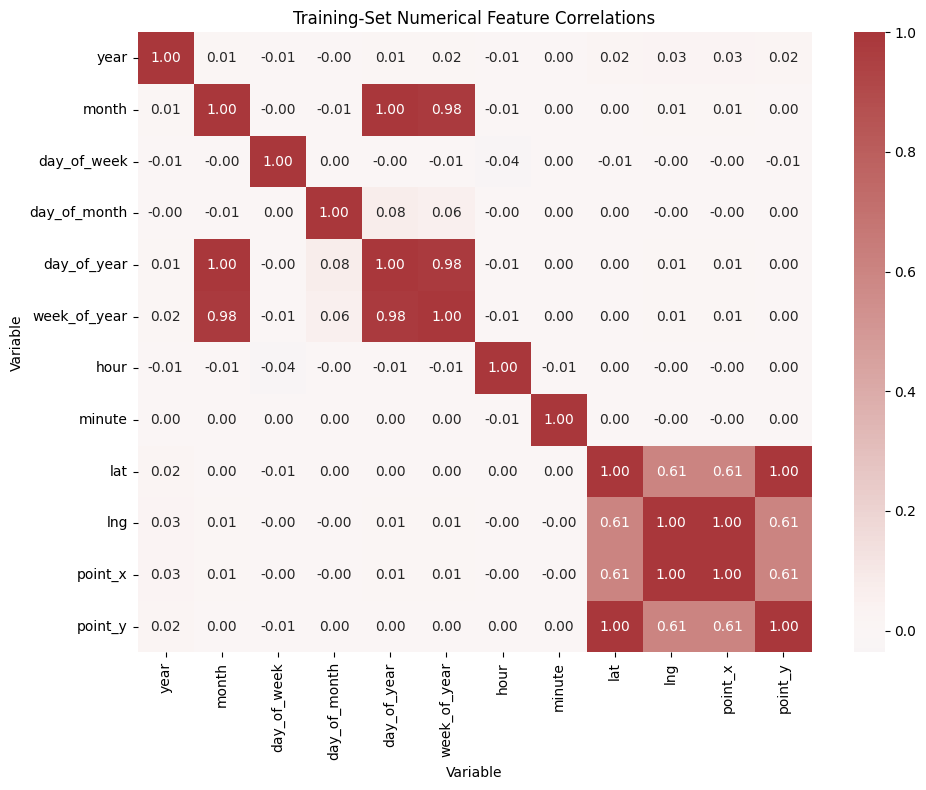

,Feature 1,Feature 2,Absolute Correlation
0,day_of_year,month,0.996362
1,week_of_year,month,0.976128
2,week_of_year,day_of_year,0.978198
3,point_x,lng,1.000000
4,point_y,lat,1.000000


In [6]:
train_numeric = X_train[numerical_features]
numeric_correlations = correlation_matrix(train_numeric)
display(numeric_correlations.round(3))
fig, ax = plot_correlation_heatmap(train_numeric, title="Training-Set Numerical Feature Correlations", figsize=(10, 8))
plt.show()
correlated_pairs = find_correlated_feature_pairs(train_numeric, threshold=0.95)
display(correlated_pairs)


## 6. Random Forest Feature Importance

The existing Random Forest implementation is fit on the complete outer training matrix only. Importance ranks refer to encoded model features, including individual one-hot columns.

In [7]:
rf_importance_path = RESULTS_DIR / "random_forest_feature_importance.csv"
if rf_importance_path.exists():
    rf_importance = pd.read_csv(rf_importance_path)
    assert set(rf_importance["Feature"]) == set(encoded_feature_names)
    print("Using the existing training-only Random Forest importance artifact.")
else:
    rf_importance_model = create_random_forest_model(random_state=RANDOM_STATE)
    rf_importance_model.fit(X_train_encoded, y_train)
    rf_importance = rank_feature_importances(rf_importance_model, encoded_feature_names)
    rf_importance.to_csv(rf_importance_path, index=False)
    del rf_importance_model
    gc.collect()
display(rf_importance)


,Feature,Importance,Rank
0,numeric__lat,0.099579,1
1,numeric__point_x,0.099548,2
2,numeric__lng,0.099498,3
3,numeric__point_y,0.099354,4
4,numeric__minute,0.091378,5
5,numeric__hour,0.089656,6
6,numeric__day_of_year,0.087327,7
7,numeric__day_of_month,0.081640,8
8,numeric__week_of_year,0.067835,9
9,numeric__day_of_week,0.057826,10


72

## 7. XGBoost Feature Importance

XGBoost uses the existing baseline factory and is fit on the same outer training matrix. Neither importance model receives test rows or labels.

In [8]:
xgb_importance_path = RESULTS_DIR / "xgboost_feature_importance.csv"
if xgb_importance_path.exists():
    xgb_importance = pd.read_csv(xgb_importance_path)
    assert set(xgb_importance["Feature"]) == set(encoded_feature_names)
    print("Using the existing training-only XGBoost importance artifact.")
else:
    xgb_importance_model = create_xgboost_model(num_classes=len(label_encoder.classes_), random_state=RANDOM_STATE)
    xgb_importance_model.fit(X_train_encoded, y_train)
    xgb_importance = rank_feature_importances(xgb_importance_model, encoded_feature_names)
    xgb_importance.to_csv(xgb_importance_path, index=False)
    del xgb_importance_model
    gc.collect()
display(xgb_importance)


,Feature,Importance,Rank
0,categorical__dc_dist_24,0.126489,1
1,numeric__hour,0.055343,2
2,numeric__year,0.050013,3
3,categorical__dc_dist_25,0.044009,4
4,categorical__dc_dist_16,0.043217,5
5,categorical__psa_2,0.036723,6
6,numeric__point_y,0.032642,7
7,categorical__dc_dist_9,0.031189,8
8,numeric__lng,0.030112,9
9,categorical__dc_dist_17,0.029409,10


78

## 8. Importance Comparison and Plots

Raw importance magnitudes can have model-specific meanings, so no normalized combined score is constructed. The table joins each model’s raw importance and rank; plots show the leading 10 and 20 encoded features separately.

,Feature,Random Forest Importance,Random Forest Rank,XGBoost Importance,XGBoost Rank
0,numeric__lat,0.099579,1,0.025492,14
1,numeric__point_x,0.099548,2,0.022671,18
2,numeric__lng,0.099498,3,0.030112,9
3,numeric__point_y,0.099354,4,0.032642,7
4,numeric__minute,0.091378,5,0.022842,17
5,numeric__hour,0.089656,6,0.055343,2
6,numeric__day_of_year,0.087327,7,0.010297,37
7,numeric__day_of_month,0.081640,8,0.005969,39
8,numeric__week_of_year,0.067835,9,0.010452,36
9,numeric__day_of_week,0.057826,10,0.017159,25


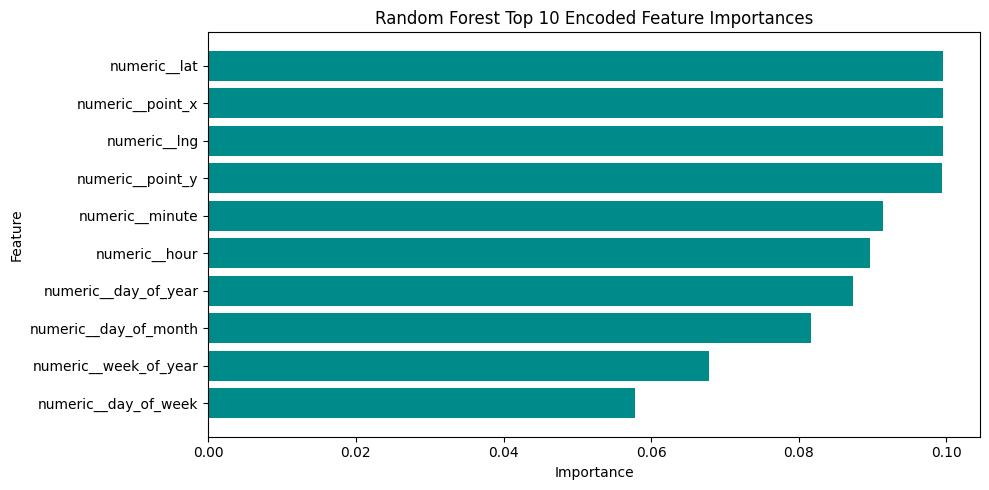

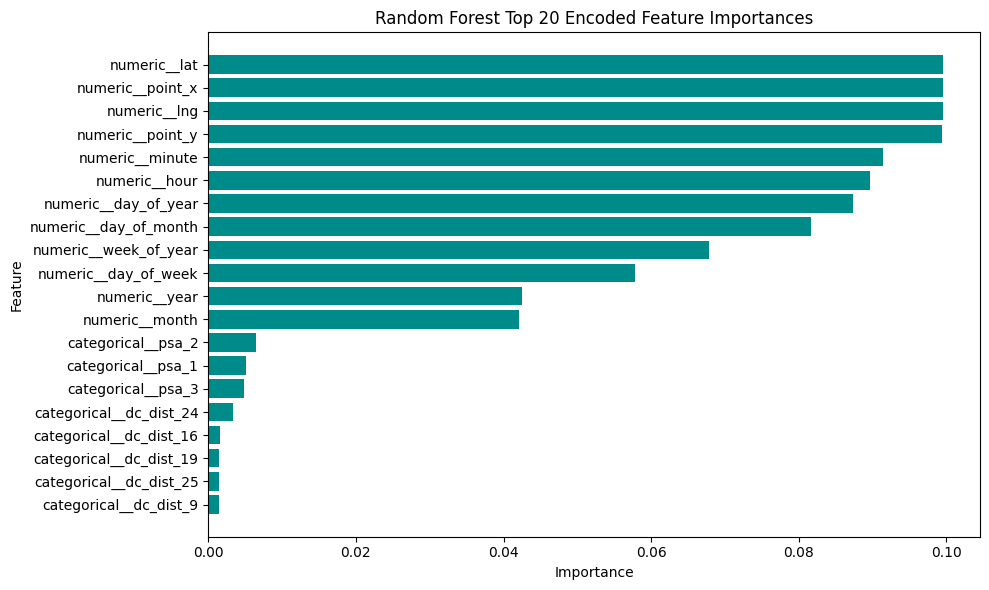

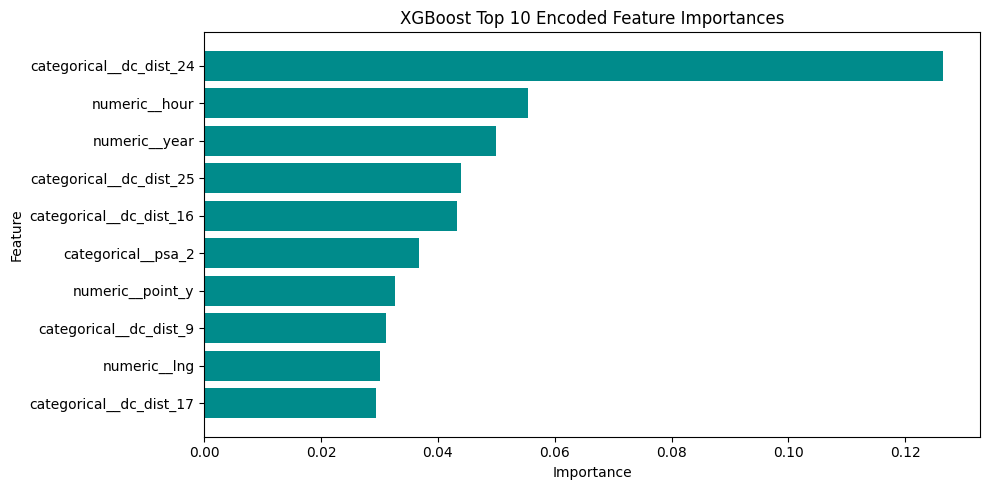

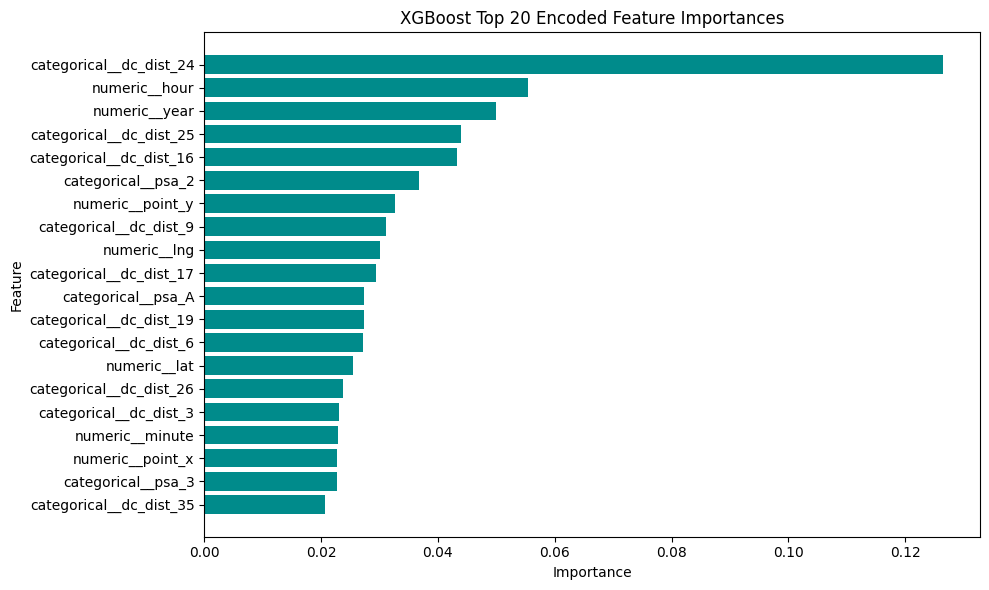

In [9]:
importance_comparison = compare_feature_importance(rf_importance, xgb_importance)
display(importance_comparison)

for model_name, table in [("Random Forest", rf_importance), ("XGBoost", xgb_importance)]:
    for top_n in (10, 20):
        fig, ax = plot_feature_importance(
            table, top_n=top_n, title=f"{model_name} Top {top_n} Encoded Feature Importances",
            figsize=(10, max(5, top_n * 0.30)),
        )
        plt.show()


## 9. Training-Only Backward Elimination

For practical runtime, a deterministic stratified sample of 25,000 outer-training rows is split into 20,000 internal training rows and 5,000 internal validation rows. The imputer/encoder is fit on only those 20,000 rows. A fresh existing Random Forest model is fit at every feature count; the least important current feature is removed and the next subset is scored by internal weighted F1. The outer test split is not passed to this process.

In [10]:
X_elim_train_raw, X_elim_valid_raw, y_elim_train, y_elim_valid = create_train_test_split(
    X_train, y_train, train_size=20000, test_size=5000, random_state=RANDOM_STATE, stratify=True
)
assert len(X_elim_train_raw) == 20000 and len(X_elim_valid_raw) == 5000

selection_preprocessor = build_preprocessor(numerical_features, categorical_features, scale_numeric=False)
X_elim_train = pd.DataFrame(
    selection_preprocessor.fit_transform(X_elim_train_raw),
    columns=selection_preprocessor.get_feature_names_out(), index=X_elim_train_raw.index,
)
X_elim_valid = pd.DataFrame(
    selection_preprocessor.transform(X_elim_valid_raw),
    columns=selection_preprocessor.get_feature_names_out(), index=X_elim_valid_raw.index,
)
assert X_elim_train.columns.tolist() == encoded_feature_names
assert X_elim_valid.columns.tolist() == encoded_feature_names
print("Internal selection sample:", len(X_elim_train), "train /", len(X_elim_valid), "validation; no outer test rows used")

selection_estimator = create_random_forest_model(random_state=RANDOM_STATE)
selection_history, final_elimination_path = backward_elimination(
    selection_estimator, X_elim_train, y_elim_train, X_elim_valid, y_elim_valid,
    min_features_to_select=1, scoring="f1_weighted",
)
selection_history.to_csv(RESULTS_DIR / "feature_selection_history.csv", index=False)
assert len(selection_history) == 39
assert selection_history.iloc[0]["Features After Count"] == 39
assert selection_history.iloc[-1]["Features After Count"] == 1
display(selection_history[["Step", "Features Before", "Removed Feature", "Features After Count", "Validation Metric", "Validation Score"]])


Internal selection sample: 20000 train / 5000 validation; no outer test rows used


,Step,Features Before,Removed Feature,Features After Count,Validation Metric,Validation Score
0,0,39,,39,f1_weighted,0.293912
1,1,39,categorical__dc_dist_77,38,f1_weighted,0.293416
2,2,38,categorical__psa_A,37,f1_weighted,0.291802
3,3,37,categorical__dc_dist_7,36,f1_weighted,0.289400
4,4,36,categorical__dc_dist_1,35,f1_weighted,0.294137
5,5,35,categorical__dc_dist_5,34,f1_weighted,0.293595
6,6,34,categorical__dc_dist_8,33,f1_weighted,0.292500
7,7,33,categorical__dc_dist_17,32,f1_weighted,0.293434
8,8,32,categorical__dc_dist_3,31,f1_weighted,0.294666
9,9,31,categorical__dc_dist_6,30,f1_weighted,0.291498


## 10. Candidate Feature Subsets and Selection Criterion

Candidate sizes are predeclared as 39, 30, 20, 15, 10, and 5, and each set follows the training-only backward-elimination path. The selected candidate is the one with the highest internal validation weighted F1 among those sizes; if scores tie, the larger subset is retained. No test score participates in this choice.

,Subset,Number of features,Internal validation weighted F1,Features
0,39-feature candidate,39,0.293912,"numeric__year, numeric__month, numeric__day_of_week, numeric__day_of_month, numeric__day_of_year, numeric__week_of_y..."
1,30-feature candidate,30,0.291498,"numeric__year, numeric__month, numeric__day_of_week, numeric__day_of_month, numeric__day_of_year, numeric__week_of_y..."
2,20-feature candidate,20,0.289356,"numeric__year, numeric__month, numeric__day_of_week, numeric__day_of_month, numeric__day_of_year, numeric__week_of_y..."
3,15-feature candidate,15,0.292954,"numeric__year, numeric__month, numeric__day_of_week, numeric__day_of_month, numeric__day_of_year, numeric__week_of_y..."
4,10-feature candidate,10,0.288798,"numeric__day_of_week, numeric__day_of_month, numeric__day_of_year, numeric__week_of_year, numeric__hour, numeric__mi..."
5,5-feature candidate,5,0.275650,"numeric__day_of_year, numeric__minute, numeric__lat, numeric__lng, numeric__point_y"


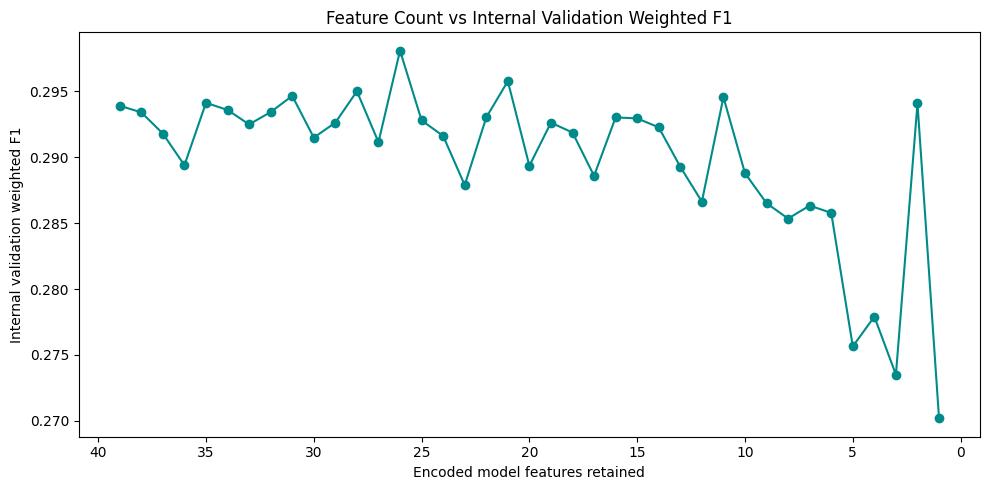

In [11]:
candidate_sizes = [39, 30, 20, 15, 10, 5]
candidate_rows = []
for size in candidate_sizes:
    row = selection_history.loc[selection_history["Features After Count"] == size].iloc[0]
    features = list(row["Features After"])
    candidate_rows.append({
        "Subset": f"{size}-feature candidate",
        "Number of features": size,
        "Internal validation weighted F1": row["Validation Score"],
        "Features": ", ".join(features),
        "Feature List": features,
    })
candidate_subsets = pd.DataFrame(candidate_rows)
display(candidate_subsets.drop(columns="Feature List"))

fig, ax = plot_feature_count_validation(selection_history)
plt.show()


## 11. Selected Feature Subset

The selection criterion uses only internal validation weighted F1 from the outer training partition. The chosen subset is saved before any test transformation or final test evaluation.

In [12]:
selected_candidate = candidate_subsets.sort_values(
    ["Internal validation weighted F1", "Number of features"],
    ascending=[False, False], kind="stable",
).iloc[0]
selected_features = list(selected_candidate["Feature List"])
selected_feature_count = len(selected_features)
print("Selected subset:", selected_candidate["Subset"])
print("Selection criterion: maximum internal validation weighted F1 among predeclared candidate sizes; ties retain more features.")
print("Selected encoded features:", selected_features)

pd.Series(selected_features, name="Feature").to_csv(RESULTS_DIR / "selected_features.txt", index=False, header=False)
pd.DataFrame({"Selection Order": np.arange(1, selected_feature_count + 1), "Feature": selected_features}).to_csv(
    RESULTS_DIR / "selected_features.csv", index=False,
)


Selected subset: 39-feature candidate
Selection criterion: maximum internal validation weighted F1 among predeclared candidate sizes; ties retain more features.
Selected encoded features: ['numeric__year', 'numeric__month', 'numeric__day_of_week', 'numeric__day_of_month', 'numeric__day_of_year', 'numeric__week_of_year', 'numeric__hour', 'numeric__minute', 'numeric__lat', 'numeric__lng', 'numeric__point_x', 'numeric__point_y', 'categorical__dc_dist_1', 'categorical__dc_dist_2', 'categorical__dc_dist_3', 'categorical__dc_dist_5', 'categorical__dc_dist_6', 'categorical__dc_dist_7', 'categorical__dc_dist_8', 'categorical__dc_dist_9', 'categorical__dc_dist_12', 'categorical__dc_dist_14', 'categorical__dc_dist_15', 'categorical__dc_dist_16', 'categorical__dc_dist_17', 'categorical__dc_dist_18', 'categorical__dc_dist_19', 'categorical__dc_dist_22', 'categorical__dc_dist_24', 'categorical__dc_dist_25', 'categorical__dc_dist_26', 'categorical__dc_dist_35', 'categorical__dc_dist_39', 'categorica

## 12. Final Test Evaluation

Feature selection is now locked. For each of the six baseline models, preprocessing is refit on the full outer training split only, the selected encoded columns are retained, and the model is evaluated once on the untouched test split. Numeric scaling remains enabled only for MLP and KNN, as in the baseline.

In [13]:
model_specs = {
    "Random Forest": (create_random_forest_model(random_state=RANDOM_STATE), False),
    "XGBoost": (create_xgboost_model(num_classes=len(label_encoder.classes_), random_state=RANDOM_STATE), False),
    "Decision Tree": (create_decision_tree_model(random_state=RANDOM_STATE), False),
    "MLP": (create_mlp_model(random_state=RANDOM_STATE), True),
    "CatBoost": (create_catboost_model(random_state=RANDOM_STATE), False),
    "KNN": (create_knn_model(), True),
}
# Test labels are encoded only now, after the selected subset has been saved.
y_test = label_encoder.transform(y_test_labels)
reduced_rows = []
reduced_timings = {}
for model_name, (estimator, scale_numeric) in model_specs.items():
    pipeline = build_encoded_subset_pipeline(
        estimator, numerical_features, categorical_features,
        encoded_feature_names, selected_features, scale_numeric=scale_numeric,
    )
    start = time.perf_counter()
    fit_start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - fit_start
    predict_start = time.perf_counter()
    prediction = pipeline.predict(X_test)
    predict_seconds = time.perf_counter() - predict_start
    metrics = evaluate_multiclass_model(y_test, prediction)
    reduced_timings[model_name] = {
        "Training Time (s)": fit_seconds,
        "Prediction Time (s)": predict_seconds,
        "Total Execution Time (s)": time.perf_counter() - start,
    }
    reduced_rows.append(add_model_result(model_name, metrics, reduced_timings[model_name]))
    print(f"{model_name}: train={fit_seconds:.1f}s, predict={predict_seconds:.1f}s")
    del pipeline, prediction
    gc.collect()
reduced_results = pd.DataFrame(reduced_rows)
assert set(reduced_results["Model"]) == set(model_specs)
display(reduced_results.sort_values("Model").reset_index(drop=True))


Random Forest: train=14.5s, predict=1.7s


XGBoost: train=24.9s, predict=0.7s


Decision Tree: train=8.5s, predict=0.3s


MLP: train=42.3s, predict=0.3s


CatBoost: train=28.4s, predict=0.5s


C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 

KNN: train=2.3s, predict=103.6s


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,Training Time (s),Prediction Time (s),Total Execution Time (s)
0,CatBoost,0.366197,0.356051,0.366197,0.286725,0.273309,0.140055,0.128615,28.387179,0.486583,28.959411
1,Decision Tree,0.292559,0.296098,0.292559,0.294211,0.203483,0.206171,0.204705,8.549386,0.253296,8.833290
2,KNN,0.299008,0.275940,0.299008,0.279465,0.200381,0.147568,0.157328,2.343230,103.618896,106.012909
3,MLP,0.366079,0.306294,0.366079,0.291867,0.277014,0.134940,0.126104,42.283680,0.325413,42.638423
4,Random Forest,0.421607,0.421614,0.421607,0.369117,0.503760,0.224061,0.256785,14.476606,1.693144,16.204939
5,XGBoost,0.382754,0.400212,0.382754,0.311068,0.458224,0.205437,0.206971,24.948139,0.659276,25.667859


## 13. Baseline vs Reduced-Subset Results

Baseline metrics are read from the verified 39-feature results file. The comparison includes all six models and the seven unchanged evaluation metrics. No composite score or model ranking is constructed.

In [14]:
baseline_results = pd.read_csv(RESULTS_DIR / "base_model_comparison_grouped.csv")
comparison_metrics = [
    "Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1",
    "Macro Precision", "Macro Recall", "Macro F1",
]
comparison = baseline_results[["Model", *comparison_metrics]].merge(
    reduced_results[["Model", *comparison_metrics]], on="Model", suffixes=(" Baseline", " Reduced"), validate="one_to_one",
)
for metric in comparison_metrics:
    comparison = comparison.rename(columns={f"{metric} Baseline": f"Baseline {metric}", f"{metric} Reduced": f"Reduced {metric}"})
comparison["Baseline Feature Count"] = 39
comparison["Reduced Feature Count"] = selected_feature_count
comparison = comparison[["Model", "Baseline Feature Count", "Reduced Feature Count"] + [
    col for metric in comparison_metrics for col in (f"Baseline {metric}", f"Reduced {metric}")
]]
comparison["Accuracy Difference"] = comparison["Reduced Accuracy"] - comparison["Baseline Accuracy"]
comparison["Weighted F1 Difference"] = comparison["Reduced Weighted F1"] - comparison["Baseline Weighted F1"]
comparison["Macro F1 Difference"] = comparison["Reduced Macro F1"] - comparison["Baseline Macro F1"]
comparison.to_csv(RESULTS_DIR / "feature_subset_comparison.csv", index=False)
display(comparison)


,Model,Baseline Feature Count,Reduced Feature Count,Baseline Accuracy,Reduced Accuracy,Baseline Weighted Precision,Reduced Weighted Precision,Baseline Weighted Recall,Reduced Weighted Recall,Baseline Weighted F1,Reduced Weighted F1,Baseline Macro Precision,Reduced Macro Precision,Baseline Macro Recall,Reduced Macro Recall,Baseline Macro F1,Reduced Macro F1,Accuracy Difference,Weighted F1 Difference,Macro F1 Difference
0,Random Forest,39,39,0.421607,0.421607,0.421614,0.421614,0.421607,0.421607,0.369117,0.369117,0.503760,0.503760,0.224061,0.224061,0.256785,0.256785,5.551115e-17,5.551115e-17,5.551115e-17
1,XGBoost,39,39,0.382754,0.382754,0.400212,0.400212,0.382754,0.382754,0.311068,0.311068,0.458224,0.458224,0.205437,0.205437,0.206971,0.206971,0.000000e+00,0.000000e+00,5.551115e-17
2,Decision Tree,39,39,0.292559,0.292559,0.296098,0.296098,0.292559,0.292559,0.294211,0.294211,0.203483,0.203483,0.206171,0.206171,0.204705,0.204705,0.000000e+00,0.000000e+00,2.775558e-17
3,MLP,39,39,0.366079,0.366079,0.306294,0.306294,0.366079,0.366079,0.291867,0.291867,0.277014,0.277014,0.134940,0.134940,0.126104,0.126104,5.551115e-17,0.000000e+00,0.000000e+00
4,CatBoost,39,39,0.366197,0.366197,0.356051,0.356051,0.366197,0.366197,0.286725,0.286725,0.273309,0.273309,0.140055,0.140055,0.128615,0.128615,5.551115e-17,5.551115e-17,0.000000e+00
5,KNN,39,39,0.299008,0.299008,0.275940,0.275940,0.299008,0.299008,0.279465,0.279465,0.200381,0.200381,0.147568,0.147568,0.157328,0.157328,5.551115e-17,0.000000e+00,5.551115e-17


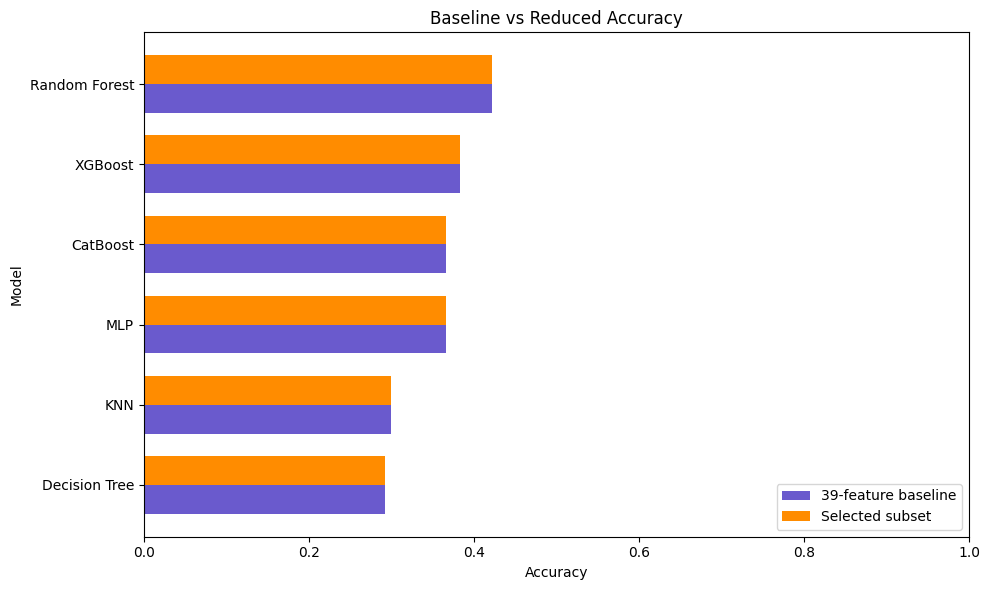

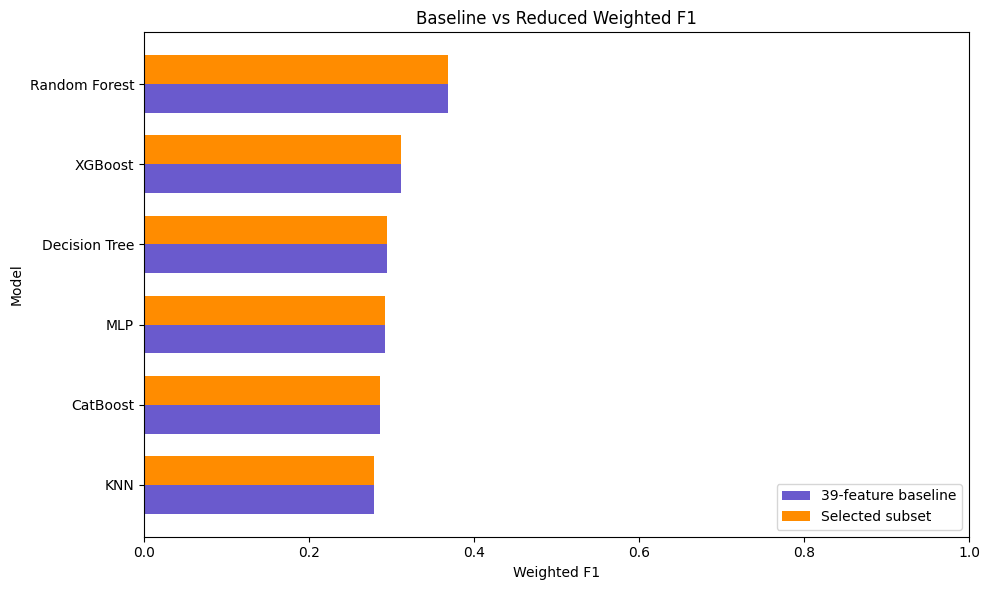

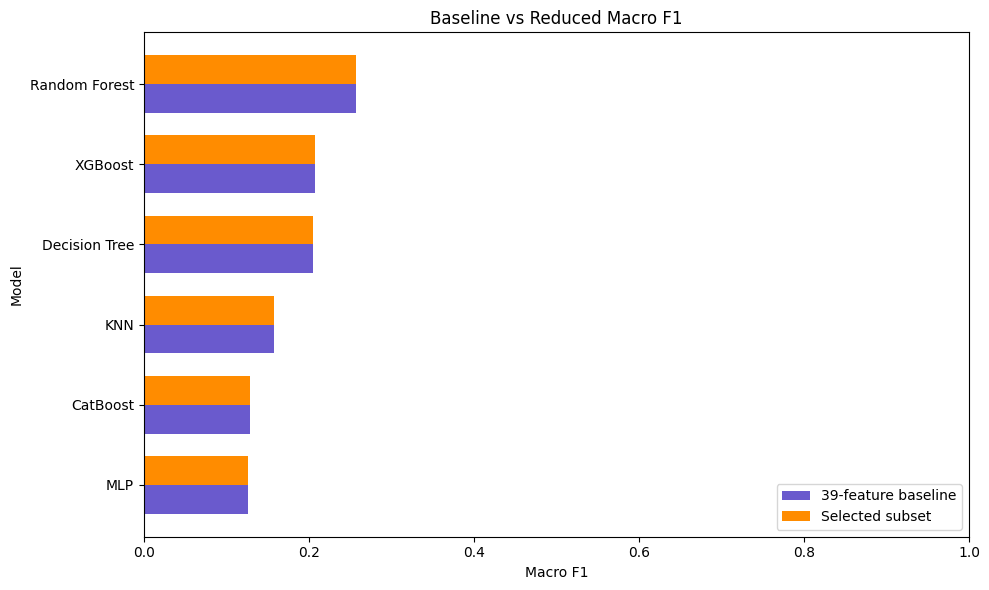

In [15]:
for metric in ("Accuracy", "Weighted F1", "Macro F1"):
    fig, ax = plot_baseline_reduced_comparison(comparison, metric, figsize=(10, 6))
    plt.show()


## 14. Leakage and Experiment Checks

The outer test set was not passed to importance fitting, correlation analysis, backward elimination, candidate comparison, or subset selection. Test labels first enter model evaluation after the selected features are saved. The final comparison uses the same target, split, random state, six model factories, and metric definitions as the baseline.

In [16]:
assert len(df) == 736033 and target == "crime_group" and len(label_encoder.classes_) == 14
assert len(source_features) == 14 and len(encoded_feature_names) == 39
assert (len(X_train), len(X_test)) == (515223, 220810)
assert not set(["crime_group", "text_general_code", "ucr_general", "objectid", "dc_key"]).intersection(X_source.columns)
assert selection_history["Validation Metric"].eq("f1_weighted").all()
assert selected_feature_count in candidate_sizes
print("Selection rows used only outer-training-derived inner train/validation data:", len(X_elim_train), "+", len(X_elim_valid))
print("Final selected feature count:", selected_feature_count)
print("Saved selection outputs:", [
    "random_forest_feature_importance.csv", "xgboost_feature_importance.csv",
    "feature_selection_history.csv", "feature_subset_comparison.csv",
    "selected_features.txt", "selected_features.csv",
])


Selection rows used only outer-training-derived inner train/validation data: 20000 + 5000
Final selected feature count: 39
Saved selection outputs: ['random_forest_feature_importance.csv', 'xgboost_feature_importance.csv', 'feature_selection_history.csv', 'feature_subset_comparison.csv', 'selected_features.txt', 'selected_features.csv']


# Teacher-Directed Feature Reduction Experiment

This is a separate, additional experiment. The preceding automatic backward-elimination experiment remains intact and selected all 39 encoded features. Here we deliberately test smaller, importance-ranked subsets and measure the trade-off. Feature-count tolerance is fixed in advance at 5% relative to full-set internal-validation weighted F1; the outer test data are used only after the reduced set is locked.

## Source-to-encoded mapping and training-only importance

The existing Random Forest and XGBoost importance files are reused. The source-level table sums the importances of all encoded child columns belonging to a source variable, separately for each estimator. Summation preserves each estimator's total importance across one-hot children; the two estimators' magnitudes are not combined. Reduction rankings use Random Forest importance to match the Random Forest internal-validation evaluator.

In [ ]:
from src.feature_selection import (
    aggregate_importance_by_source, build_encoded_reduction_candidates,
    build_source_reduction_candidates, evaluate_reduction_candidates,
)
from src.visualization import plot_reduction_validation
from src.evaluation import evaluate_multiclass_model

# encoded_schema was learned from outer training rows in the first experiment.
source_encoded_mapping = encoded_schema[["Encoded Feature", "Source Feature"]].copy()
assert source_encoded_mapping["Encoded Feature"].tolist() == encoded_feature_names
print("Source features:", source_encoded_mapping["Source Feature"].nunique())
print("Encoded model features:", len(source_encoded_mapping))
display(source_encoded_mapping.groupby("Source Feature", sort=False)["Encoded Feature"].apply(list).rename("Encoded Features").reset_index())

rf_source_importance = aggregate_importance_by_source(rf_importance, source_encoded_mapping)
xgb_source_importance = aggregate_importance_by_source(xgb_importance, source_encoded_mapping).rename(columns={
    "Importance": "XGBoost Importance", "Rank": "XGBoost Rank", "Encoded Features": "Encoded Features (XGBoost)"
})
rf_source_importance = rf_source_importance.rename(columns={"Importance":"Random Forest Importance", "Rank":"Random Forest Rank", "Encoded Features":"Encoded Features (Random Forest)"})
source_importance = rf_source_importance.merge(xgb_source_importance, on="Source Feature", validate="one_to_one")
source_importance.to_csv(RESULTS_DIR / "source_feature_importance.csv", index=False)
display(source_importance)

importance_view = rf_importance[["Feature", "Importance", "Rank"]].rename(columns={"Importance":"Random Forest Importance", "Rank":"RF Rank"}).merge(
    xgb_importance[["Feature", "Importance", "Rank"]].rename(columns={"Importance":"XGBoost Importance", "Rank":"XGBoost Rank"}), on="Feature", validate="one_to_one"
).sort_values("RF Rank")
display(importance_view)


## Reduction strategies and candidate definitions

**Encoded-level:** rank individual encoded columns by training-only Random Forest importance and retain the top requested counts 39, 30, 25, 20, 15, and 10. **Source-level:** rank source variables by the sum of their Random Forest child-column importances, then remove whole low-ranked source groups. Because source variables produce different numbers of encoded columns, source-level counts may fall below a requested threshold; the exact retained and removed names are shown. These rankings identify candidate subsets, not proof that any low-ranked feature is useless.

In [ ]:
candidate_counts = [39, 30, 25, 20, 15, 10]
encoded_candidates = build_encoded_reduction_candidates(rf_importance, candidate_counts)
rf_source_only = rf_source_importance.rename(columns={"Random Forest Importance":"Importance"})[["Source Feature", "Importance", "Rank", "Encoded Features (Random Forest)"]].rename(columns={"Encoded Features (Random Forest)":"Encoded Features"})
source_candidates = build_source_reduction_candidates(rf_source_only, source_encoded_mapping, candidate_counts)
all_candidates = pd.concat([encoded_candidates, source_candidates], ignore_index=True, sort=False)
all_candidates["Removed Source Features"] = all_candidates["Removed Features"].apply(
    lambda removed: list(dict.fromkeys(source_encoded_mapping.set_index("Encoded Feature").loc[removed, "Source Feature"].tolist())) if removed else []
)
all_candidates["Selection Rationale"] = all_candidates["Rationale"]
display(all_candidates[["Strategy", "Requested Feature Count", "Feature Count", "Retained Features", "Removed Features", "Removed Source Features", "Selection Rationale"]].to_string(index=False))


## Internal validation (selection stage)

The same Random Forest factory used for feature ranking evaluates each candidate on the already-created 20,000-row internal training split and 5,000-row internal validation split, both drawn only from the outer training partition. Weighted F1 is the primary metric; accuracy and macro F1 are secondary. No outer test rows or labels enter candidate scoring.

In [ ]:
reduction_validation = evaluate_reduction_candidates(
    create_random_forest_model(random_state=RANDOM_STATE),
    X_elim_train, y_elim_train, X_elim_valid, y_elim_valid, all_candidates.to_dict("records"),
)
reduction_results = all_candidates.drop(columns=["Rationale"], errors="ignore").merge(
    reduction_validation, on=["Strategy", "Requested Feature Count", "Feature Count"], validate="one_to_one"
)
validation_table = reduction_results[["Strategy", "Requested Feature Count", "Feature Count", "Validation Accuracy", "Validation Weighted F1", "Validation Macro F1"]].sort_values(
    ["Strategy", "Feature Count"], ascending=[True, False]
)
display(validation_table)
for metric in ("Weighted F1", "Accuracy", "Macro F1"):
    fig, ax = plot_reduction_validation(reduction_results, metric)
    plt.show()


## Locking the teacher-directed reduced subset

Before final test evaluation, the full-set reference is the 39-feature encoded-level candidate's internal-validation weighted F1. A reduced candidate qualifies when its weighted F1 is at least 95% of that reference. Among qualifying candidates, select the smallest; if none qualifies, select the smaller candidate with the highest validation weighted F1 and label it a sensitivity-analysis subset. This rule guarantees a reduced set for investigation without claiming it is objectively best. The chosen feature names are saved before test labels are transformed or used.

In [ ]:
full_validation_f1 = float(reduction_results.loc[
    (reduction_results["Strategy"] == "Encoded-level") & (reduction_results["Feature Count"] == 39),
    "Validation Weighted F1",
].iloc[0])
relative_tolerance = 0.05  # fixed before looking at final test results
minimum_acceptable_f1 = full_validation_f1 * (1 - relative_tolerance)
reduced_candidates = reduction_results[reduction_results["Feature Count"] < 39].copy()
qualifying = reduced_candidates[reduced_candidates["Validation Weighted F1"] >= minimum_acceptable_f1]
if not qualifying.empty:
    locked_row = qualifying.sort_values(["Feature Count", "Validation Weighted F1"], ascending=[True, False], kind="stable").iloc[0]
    locked_status = "Within predeclared 5% validation tolerance"
else:
    locked_row = reduced_candidates.sort_values(["Validation Weighted F1", "Feature Count"], ascending=[False, True], kind="stable").iloc[0]
    locked_status = "Sensitivity-analysis subset; no reduced candidate met the predeclared 5% tolerance"
locked_features = list(locked_row["Retained Features"])
locked_count = len(locked_features)
removed_features = [name for name in encoded_feature_names if name not in set(locked_features)]
locked_source_names = set(source_encoded_mapping.loc[source_encoded_mapping["Encoded Feature"].isin(locked_features), "Source Feature"])
removed_source_names = [name for name in source_features if name not in locked_source_names]
print("LOCKED subset:", locked_row["Strategy"], locked_count, "features;", locked_status)
print("Fixed tolerance:", relative_tolerance, "| full validation weighted F1:", full_validation_f1, "| minimum:", minimum_acceptable_f1)
print("Removed encoded features:", removed_features)
print("Whole source features removed:", removed_source_names)

importance_lookup = rf_importance.set_index("Feature")["Importance"]
source_lookup = source_encoded_mapping.set_index("Encoded Feature")["Source Feature"]
locked_manifest = pd.DataFrame({
    "Feature Name": encoded_feature_names,
    "Source Feature": [source_lookup.loc[name] for name in encoded_feature_names],
    "Status": ["Retained" if name in set(locked_features) else "Removed" for name in encoded_feature_names],
    "Random Forest Importance": [float(importance_lookup.loc[name]) for name in encoded_feature_names],
    "Selection Reason": [
        (f"Retained in {locked_row['Strategy']} subset under predeclared rule: {locked_status}.") if name in set(locked_features)
        else (f"Removed as part of source-level elimination ({source_lookup.loc[name]})." if locked_row["Strategy"] == "Source-level" and source_lookup.loc[name] in removed_source_names
              else "Excluded by ascending training-only Random Forest encoded-feature importance ranking.")
        for name in encoded_feature_names
    ],
})
locked_manifest.to_csv(RESULTS_DIR / "teacher_directed_selected_features.csv", index=False)
locked_manifest.loc[locked_manifest["Status"] == "Retained", "Feature Name"].to_csv(
    RESULTS_DIR / "teacher_directed_selected_features.txt", index=False, header=False
)
display(locked_manifest)
assert 0 < locked_count < 39


## Final test evaluation (subset locked)

Only after the manifest above is written do we encode the untouched test labels and evaluate the six existing model factories. Model parameters, outer split, preprocessing definitions, and metric calculations match the 39-feature baseline. Test performance is reported as an outcome and does not alter the locked subset.

In [ ]:
# The reduced feature set is now locked. Test labels are first accessed here.
y_test = label_encoder.transform(y_test_labels)
teacher_model_specs = {
    "Random Forest": (create_random_forest_model(random_state=RANDOM_STATE), False),
    "XGBoost": (create_xgboost_model(num_classes=len(label_encoder.classes_), random_state=RANDOM_STATE), False),
    "Decision Tree": (create_decision_tree_model(random_state=RANDOM_STATE), False),
    "MLP": (create_mlp_model(random_state=RANDOM_STATE), True),
    "CatBoost": (create_catboost_model(random_state=RANDOM_STATE), False),
    "KNN": (create_knn_model(), True),
}
teacher_test_rows = []
for model_name, (estimator, scale_numeric) in teacher_model_specs.items():
    reduced_pipeline = build_encoded_subset_pipeline(
        estimator, numerical_features, categorical_features, encoded_feature_names,
        locked_features, scale_numeric=scale_numeric,
    )
    reduced_pipeline.fit(X_train, y_train)
    prediction = reduced_pipeline.predict(X_test)
    teacher_test_rows.append({"Model": model_name, **evaluate_multiclass_model(y_test, prediction)})
teacher_reduced_results = pd.DataFrame(teacher_test_rows)
baseline_metrics = pd.read_csv(RESULTS_DIR / "base_model_comparison_grouped.csv")
reduction_comparison = baseline_metrics[["Model", "Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1", "Macro Precision", "Macro Recall", "Macro F1"]].merge(
    teacher_reduced_results, on="Model", suffixes=(" Baseline", " Reduced"), validate="one_to_one"
)
reduction_comparison.insert(1, "Baseline Feature Count", 39)
reduction_comparison.insert(2, "Reduced Feature Count", locked_count)
for metric in ("Accuracy", "Weighted F1", "Macro F1"):
    reduction_comparison[f"{metric} Difference"] = reduction_comparison[f"{metric} Reduced"] - reduction_comparison[f"{metric} Baseline"]
    reduction_comparison[f"Relative {metric} Change"] = 100 * reduction_comparison[f"{metric} Difference"] / reduction_comparison[f"{metric} Baseline"]
reduction_comparison.to_csv(RESULTS_DIR / "teacher_directed_feature_reduction_comparison.csv", index=False)
display(reduction_comparison)
for metric in ("Accuracy", "Weighted F1", "Macro F1"):
    fig, ax = plot_baseline_reduced_comparison(reduction_comparison, metric, figsize=(10, 6))
    plt.show()


## Teacher-facing summary and verification

The results below report the dimensionality change, validation change used for selection, and each model's untouched-test weighted F1 before and after reduction. Performance differences are empirical; a lower feature count does not imply an improvement.

In [ ]:
teacher_summary = pd.DataFrame({
    "Model": reduction_comparison["Model"],
    "Full Feature Set": 39,
    "Reduced Feature Set": locked_count,
    "Features Removed": 39 - locked_count,
    "Percentage Reduction": 100 * (39 - locked_count) / 39,
    "Validation Weighted F1 (RF full set)": full_validation_f1,
    "Validation Weighted F1 (locked subset)": float(locked_row["Validation Weighted F1"]),
    "Test Weighted F1 (baseline)": reduction_comparison["Weighted F1 Baseline"],
    "Test Weighted F1 (reduced)": reduction_comparison["Weighted F1 Reduced"],
})
display(teacher_summary)
print("Reduction strategy:", locked_row["Strategy"])
print("Features removed:", removed_features)
print("Features retained:", locked_features)
print("Whole source features removed:", removed_source_names)
print("Validation weighted-F1 change:", float(locked_row["Validation Weighted F1"]) - full_validation_f1)
print("Test set remained outside feature ranking, candidate construction, validation scoring, and locking: True")
assert len(source_encoded_mapping) == 39 and source_encoded_mapping["Source Feature"].nunique() == 14
assert locked_count < 39 and len(teacher_reduced_results) == 6
assert not set(["crime_group", "text_general_code", "ucr_general", "objectid", "dc_key"]).intersection(X_train.columns)
print("Saved teacher-directed outputs: source_feature_importance.csv, teacher_directed_selected_features.csv, teacher_directed_selected_features.txt, teacher_directed_feature_reduction_comparison.csv")
